# Lane Departure Avoidance & Lane-Change Validation — v3

**Notebook reestructurado, orientado a objetos, y ya conectado a percepcion real.**

Respecto a la v2, esta version agrega:

1. El setup completo de **YOLOPv2** (clonar, pesos, parche para correr en CPU) con los bugs ya resueltos.
2. Un **video real** de prueba (Udacity `CarND-LaneLines-P1`), para dejar de depender solo de imagenes sueltas.
3. La prueba de `ClassicalLaneDetector` (OpenCV) sobre un frame real del video, no solo sobre una imagen sintetica.
4. `demo.py` de YOLOPv2 corriendo sobre el video real.
5. **Pruebas unitarias** de la logica de decision (Lane Keeping + Lane-Change Validation), sin depender de ninguna imagen ni video.

Importante para no perder el hilo: las secciones 0.x (YOLOPv2 + video) y la seccion de pruebas unitarias son piezas **todavia no conectadas entre si** — cada una corre por separado. Conectarlas (sacar los numeros crudos de YOLOPv2, convertirlos de pixeles a metros, y alimentar con eso al `Simulator`) es el siguiente paso, marcado en la seccion final de roadmap.


## 0. Instalación de dependencias base

Para la simulación y la detección clásica de carril.

In [ ]:
# pip install opencv-python numpy matplotlib
# %pip install torch

## 0.1 YOLOPv2 — clonar el repositorio

Detector conjunto de carril + área transitable + vehículos.


In [2]:
# !git clone https://github.com/CAIC-AD/YOLOPv2

## 0.2 YOLOPv2 — descargar pesos y organizarlos

`demo.py` espera el archivo de pesos en `data/weights/yolopv2.pt` dentro del repo,
no en la raíz. También instalamos las dependencias propias del repo.

Nota: el `requirements.txt` pide `torch==1.7.0`, una versión que ya no existe para
Python moderno. Ese error de pip es inofensivo — Colab ya trae una versión reciente
de PyTorch preinstalada y es la que se usa.


In [3]:
# !wget https://github.com/CAIC-AD/YOLOPv2/releases/download/V0.0.1/yolopv2.pt -P YOLOPv2/
# !mkdir -p YOLOPv2/data/weights
# !mv YOLOPv2/yolopv2.pt YOLOPv2/data/weights/yolopv2.pt
# !pip install -r YOLOPv2/requirements.txt


## 0.3 YOLOPv2 — parchear `demo.py` para correr en CPU

El archivo de pesos fue guardado pensando en GPU (backend CUDA). Sin GPU en la sesión,
`torch.jit.load(weights)` truena. Este parche fuerza la carga a CPU sin tocar nada más
del script.


In [4]:
!sed -i "s/torch\.jit\.load(weights)/torch.jit.load(weights, map_location='cpu')/" YOLOPv2/demo.py
!grep -n "torch.jit.load" YOLOPv2/demo.py   # debe mostrar map_location='cpu'

'sed' is not recognized as an internal or external command,
operable program or batch file.
'grep' is not recognized as an internal or external command,
operable program or batch file.


## 0.4 YOLOPv2 — prueba de inferencia sobre la imagen de ejemplo

Primero sobre una sola imagen (la que trae el repo), para confirmar que todo el setup
funciona antes de pasar a video. `--device cpu` evita el error de CUDA no disponible.


In [5]:
%cd YOLOPv2
!python demo.py --source data/example.jpg --device cpu
%cd ..


c:\Users\Sistemas\Documents\TECMO\Semestre 7\Codigos\Proyecto\Lane-Departure-Avoidance\YOLOPv2


Traceback (most recent call last):
  File "c:\Users\Sistemas\Documents\TECMO\Semestre 7\Codigos\Proyecto\Lane-Departure-Avoidance\YOLOPv2\demo.py", line 5, in <module>
    import torch
ModuleNotFoundError: No module named 'torch'


c:\Users\Sistemas\Documents\TECMO\Semestre 7\Codigos\Proyecto\Lane-Departure-Avoidance


In [6]:
import glob
import cv2
import matplotlib.pyplot as plt

# Busca automaticamente la carpeta de salida mas reciente (exp, exp1, exp2, ...)
output_dirs = sorted(glob.glob("YOLOPv2/runs/detect/exp*"))
if output_dirs:
    latest_dir = output_dirs[-1]
    result_imgs = glob.glob(f"{latest_dir}/*.jpg")
    if result_imgs:
        img = cv2.imread(result_imgs[0])
        plt.figure(figsize=(10, 6))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(f"Resultado de YOLOPv2: {result_imgs[0]}")
        plt.axis("off")
        plt.show()
    else:
        print("No se encontro imagen de resultado en", latest_dir)
else:
    print("Aun no hay carpeta de salida. Revisa si demo.py corrio sin errores arriba.")


Aun no hay carpeta de salida. Revisa si demo.py corrio sin errores arriba.


## 0.5 Video real de prueba (Udacity `CarND-LaneLines-P1`)

Repositorio público con videos cortos de dashcam, hechos justo para practicar
detección de carril. Empezamos con `solidWhiteRight.mp4` (el más simple: carretera
recta, buena luz). `challenge.mp4` es el más difícil (sombras, cambios de color en el
pavimento) — déjalo para después.


In [7]:
!git clone https://github.com/udacity/CarND-LaneLines-P1
!ls CarND-LaneLines-P1/test_videos/

TEST_VIDEO_PATH = "CarND-LaneLines-P1/test_videos/solidWhiteRight.mp4"


fatal: destination path 'CarND-LaneLines-P1' already exists and is not an empty directory.
'ls' is not recognized as an internal or external command,
operable program or batch file.


## 1. Importaciones

In [8]:
import math
from dataclasses import dataclass, field
from typing import List, Optional, Tuple

import numpy as np
import matplotlib.pyplot as plt

try:
    import cv2
    CV2_AVAILABLE = True
except ImportError:
    CV2_AVAILABLE = False
    print("OpenCV no disponible en este entorno; la deteccion de carril con imagenes reales no podra ejecutarse.")


## 2. Parametros del sistema

Todo lo que antes eran variables sueltas ahora vive en `dataclasses`. Esto evita el bug del notebook original donde `LAME_WIDTH`/`LANE_WIDTH` y `LANE_CENTER`/`LANE_HEADING` no coincidian entre celdas.

In [9]:
@dataclass
class VehicleParams:
    length: float = 4.963       # m
    wheelbase: float = 2.9      # m
    width: float = 1.96         # m
    mass: float = 2150          # kg


@dataclass
class ControlParams:
    k_lateral: float = 0.8
    k_heading: float = 1.2
    max_steering_angle: float = np.deg2rad(30)


@dataclass
class SafetyParams:
    min_safe_distance: float = 10.0     # m
    min_safe_ttc: float = 3.0           # s  (parametro de simulacion, no validado para uso automotriz)
    lane_safety_margin: float = 0.30    # m


@dataclass
class SimulationParams:
    dt: float = 0.05
    total_time: float = 10.0


@dataclass
class LaneState:
    center: float = 0.0      # m, offset lateral del centro del carril
    heading: float = 0.0     # rad
    width: float = 3.5       # m


@dataclass
class VehicleState:
    x: float = 0.0
    y: float = 0.0
    yaw: float = 0.0
    speed: float = 15.0      # m/s (simulado; en el vehiculo real vendria de percepcion, no de CAN)


## 3. Modelo cinematico (Bicycle Model)

Encapsula lo que antes eran las funciones sueltas `bicycle_model` y `update_vehicle_state`.

In [10]:
class KinematicBicycleModel:
    """Modelo cinematico de bicicleta. No pretende ser un modelo dinamico completo,
    solo mostrar como cambia la posicion del vehiculo al aplicar una direccion."""

    def __init__(self, vehicle: VehicleParams):
        self.vehicle = vehicle

    def derivatives(self, state: VehicleState, steering_angle: float) -> Tuple[float, float, float]:
        x_dot = state.speed * np.cos(state.yaw)
        y_dot = state.speed * np.sin(state.yaw)
        yaw_dot = (state.speed / self.vehicle.wheelbase) * np.tan(steering_angle)
        return x_dot, y_dot, yaw_dot

    def step(self, state: VehicleState, steering_angle: float, dt: float) -> VehicleState:
        x_dot, y_dot, yaw_dot = self.derivatives(state, steering_angle)
        return VehicleState(
            x=state.x + x_dot * dt,
            y=state.y + y_dot * dt,
            yaw=state.yaw + yaw_dot * dt,
            speed=state.speed,
        )


## 4. Geometria del carril y errores de control (Lane Keeping)

In [11]:
class LaneGeometry:
    """Calculos geometricos del carril: limites, error lateral, error de orientacion
    y deteccion de riesgo de salida."""

    @staticmethod
    def boundaries(lane: LaneState) -> Tuple[float, float]:
        left = lane.center + lane.width / 2
        right = lane.center - lane.width / 2
        return left, right

    @staticmethod
    def lateral_error(vehicle_y: float, lane: LaneState) -> float:
        return vehicle_y - lane.center

    @staticmethod
    def heading_error(vehicle_yaw: float, lane: LaneState) -> float:
        return vehicle_yaw - lane.heading

    @staticmethod
    def is_departing(vehicle_y: float, lane: LaneState, vehicle: VehicleParams, safety: SafetyParams) -> bool:
        left, right = LaneGeometry.boundaries(lane)
        vehicle_left = vehicle_y + vehicle.width / 2
        vehicle_right = vehicle_y - vehicle.width / 2
        safe_left = left - safety.lane_safety_margin
        safe_right = right + safety.lane_safety_margin
        return vehicle_left > safe_left or vehicle_right < safe_right


## 5. Controlador de Lane Keeping

In [12]:
class LaneKeepingController:
    """Ley de control: delta = -(K_lateral * e_y + K_heading * e_psi), saturada.
    El resultado es una correccion de direccion DESEADA, no una orden fisica al volante."""

    def __init__(self, control: ControlParams):
        self.control = control

    def compute_steering(self, lateral_error: float, heading_error: float) -> float:
        steering = -(
            self.control.k_lateral * lateral_error
            + self.control.k_heading * heading_error
        )
        return float(np.clip(steering, -self.control.max_steering_angle, self.control.max_steering_angle))


## 6. Deteccion de carril con OpenCV (pipeline clasico)

Sigue el pipeline clasico recomendado en el documento del proyecto: grayscale -> blur
-> Canny -> ROI -> Hough -> ajuste de lineas -> estimacion de centro/heading del carril
en pixeles.

Nota importante: esto entrega el carril en **coordenadas de imagen (pixeles)**. Para
usarlo dentro del `LaneState` (en metros) hace falta una calibracion camara->mundo
(homografia / bird's-eye view) que todavia no esta implementada aqui; se deja marcada
como TODO porque depende de la camara real que se use (AUMOVIO FSC 332).


=== Prueba con imagen sintetica ===
left_fit: (np.float64(-1.537950315520409), np.float64(708.3607476635515))
right_fit: (np.float64(1.4240673948284568), np.float64(-234.70056626538042))
center_px estimado: 324.55429474558036


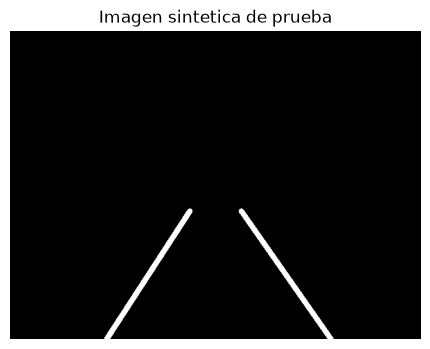

In [13]:
class ClassicalLaneDetector:
    """Pipeline clasico de deteccion de carril sobre una imagen de camara frontal."""

    def __init__(self, canny_low: int = 50, canny_high: int = 150):
        if not CV2_AVAILABLE:
            raise RuntimeError("OpenCV no esta disponible en este entorno.")
        self.canny_low = canny_low
        self.canny_high = canny_high

    def preprocess(self, frame: np.ndarray) -> np.ndarray:
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        blurred = cv2.GaussianBlur(gray, (5, 5), 0)
        return blurred

    def edges(self, gray_blurred: np.ndarray) -> np.ndarray:
        return cv2.Canny(gray_blurred, self.canny_low, self.canny_high)

    def region_of_interest(self, edges_img: np.ndarray) -> np.ndarray:
        height, width = edges_img.shape
        polygon = np.array([[
            (int(0.05 * width), height),
            (int(0.45 * width), int(0.6 * height)),
            (int(0.55 * width), int(0.6 * height)),
            (int(0.95 * width), height),
        ]], dtype=np.int32)
        mask = np.zeros_like(edges_img)
        cv2.fillPoly(mask, polygon, 255)
        return cv2.bitwise_and(edges_img, mask)

    def hough_lines(self, roi_edges: np.ndarray) -> Optional[np.ndarray]:
        return cv2.HoughLinesP(
            roi_edges, rho=2, theta=np.pi / 180, threshold=50,
            minLineLength=40, maxLineGap=100,
        )

    def fit_lane_lines(self, lines: Optional[np.ndarray], img_width: int) -> Tuple[Optional[Tuple], Optional[Tuple]]:
        """Separa lineas en izquierda/derecha por pendiente y promedia cada grupo.
        Devuelve (left_fit, right_fit) como (pendiente, intercepto) o None si no hay datos."""
        left_fits, right_fits = [], []
        if lines is None:
            return None, None
        for line in lines:
            x1, y1, x2, y2 = line.reshape(-1)  # soporta forma (N,1,4) y (N,4) segun la version de OpenCV
            if x2 == x1:
                continue
            slope = (y2 - y1) / (x2 - x1)
            intercept = y1 - slope * x1
            if slope < -0.3:
                left_fits.append((slope, intercept))
            elif slope > 0.3:
                right_fits.append((slope, intercept))
        left_fit = tuple(np.mean(left_fits, axis=0)) if left_fits else None
        right_fit = tuple(np.mean(right_fits, axis=0)) if right_fits else None
        return left_fit, right_fit

    def estimate_lane_center_px(self, left_fit, right_fit, img_width: int, y_eval: float) -> Optional[float]:
        """Centro estimado del carril en pixeles, a la altura y_eval. TODO: convertir
        a metros con una homografia calibrada para poder alimentar LaneState."""
        def x_at_y(fit):
            slope, intercept = fit
            if slope == 0:
                return None
            return (y_eval - intercept) / slope

        if left_fit is not None and right_fit is not None:
            xl, xr = x_at_y(left_fit), x_at_y(right_fit)
            if xl is not None and xr is not None:
                return (xl + xr) / 2
        return None

    def process(self, frame: np.ndarray):
        gray_blurred = self.preprocess(frame)
        edge_img = self.edges(gray_blurred)
        roi_edges = self.region_of_interest(edge_img)
        lines = self.hough_lines(roi_edges)
        left_fit, right_fit = self.fit_lane_lines(lines, frame.shape[1])
        center_px = self.estimate_lane_center_px(left_fit, right_fit, frame.shape[1], frame.shape[0] * 0.95)
        return {"left_fit": left_fit, "right_fit": right_fit, "center_px": center_px, "lines": lines}


# Prueba rapida con una imagen sintetica (dos lineas de carril dibujadas a mano),
# solo para validar que el pipeline corre sin depender de ningun archivo externo.
if CV2_AVAILABLE:
    synthetic = np.zeros((480, 640, 3), dtype=np.uint8)
    cv2.line(synthetic, (150, 480), (280, 280), (255, 255, 255), 8)
    cv2.line(synthetic, (500, 480), (360, 280), (255, 255, 255), 8)

    detector = ClassicalLaneDetector()
    result = detector.process(synthetic)
    print("=== Prueba con imagen sintetica ===")
    print("left_fit:", result["left_fit"])
    print("right_fit:", result["right_fit"])
    print("center_px estimado:", result["center_px"])

    plt.figure(figsize=(6, 4))
    plt.imshow(cv2.cvtColor(synthetic, cv2.COLOR_BGR2RGB))
    plt.title("Imagen sintetica de prueba")
    plt.axis("off")
    plt.show()


## 6.1 Prueba de `ClassicalLaneDetector` sobre un frame REAL del video

Ahora sobre un frame de verdad, tomado del video de Udacity descargado en la seccion 0.5.
Esta es la primera vez que el pipeline corre sobre una carretera real, no dibujada a mano.


=== Prueba con frame real (Udacity) ===
left_fit: (np.float64(-0.7484659792389154), np.float64(661.4124803083861))
right_fit: (np.float64(0.6302560232660767), np.float64(0.4121221545715506))
center_px estimado: 505.7949586451927


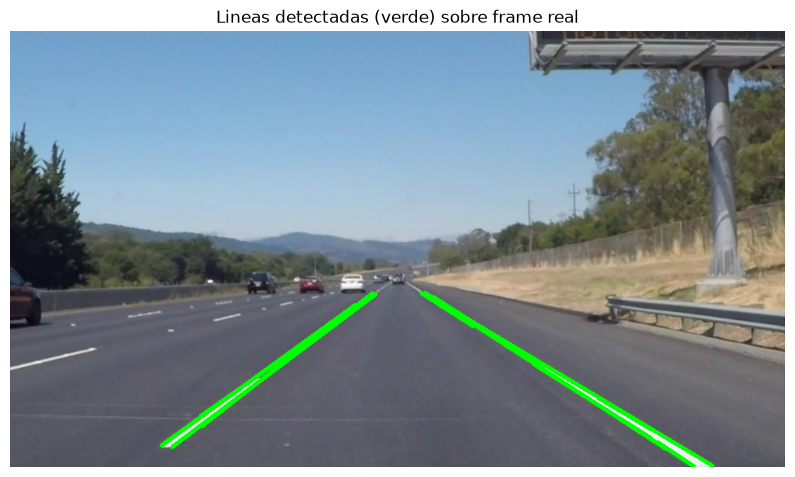

In [14]:
if CV2_AVAILABLE:
    cap = cv2.VideoCapture(TEST_VIDEO_PATH)
    ret, real_frame = cap.read()
    cap.release()

    if not ret:
        print("No se pudo leer el video. Revisa que la seccion 0.5 se haya corrido bien.")
    else:
        detector = ClassicalLaneDetector()
        result = detector.process(real_frame)
        print("=== Prueba con frame real (Udacity) ===")
        print("left_fit:", result["left_fit"])
        print("right_fit:", result["right_fit"])
        print("center_px estimado:", result["center_px"])

        # Dibuja las lineas detectadas sobre el frame para inspeccionar visualmente
        overlay = real_frame.copy()
        if result["lines"] is not None:
            for line in result["lines"]:
                x1, y1, x2, y2 = line.reshape(-1)
                cv2.line(overlay, (x1, y1), (x2, y2), (0, 255, 0), 3)

        plt.figure(figsize=(10, 6))
        plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        plt.title("Lineas detectadas (verde) sobre frame real")
        plt.axis("off")
        plt.show()


## 7. Deteccion de objetos con red preentrenada (YOLO / YOLOPv2)

Interfaz generica de deteccion, intercambiable entre un YOLO estandar (`ultralytics`) o
YOLOPv2 (ya preparado en la seccion 0). La red NO decide si un cambio de carril es
seguro; solo responde preguntas de percepcion: hay un vehiculo, donde esta, que clase
es, que tan confiable es.


In [15]:
@dataclass
class Detection:
    bbox: Tuple[float, float, float, float]  # x1, y1, x2, y2 en pixeles
    class_name: str
    confidence: float


class VehicleDetector:
    """Interfaz generica de deteccion de vehiculos/objetos."""

    def __init__(self, weights_path: Optional[str] = None, backend: str = "ultralytics"):
        self.backend = backend
        self.model = None
        if weights_path is not None:
            self._load(weights_path)

    def _load(self, weights_path: str):
        if self.backend == "ultralytics":
            from ultralytics import YOLO  # import perezoso: solo si se usa este backend
            self.model = YOLO(weights_path)
        elif self.backend == "yolopv2":
            # La forma recomendada de usar YOLOPv2 hoy es via demo.py (seccion 0.4/7.1),
            # que ya trae su propio pre/post-procesamiento correcto y probado.
            # Integrarlo aqui como libreria importable es el TODO del roadmap (seccion final).
            raise NotImplementedError("Integracion directa de YOLOPv2 como libreria pendiente; usar demo.py por ahora.")
        else:
            raise ValueError(f"Backend no soportado: {self.backend}")

    def detect(self, frame: np.ndarray) -> List[Detection]:
        if self.model is None:
            raise RuntimeError("Modelo no cargado. Pasa weights_path al construir VehicleDetector.")
        results = self.model(frame)
        detections = []
        for r in results:
            for box in r.boxes:
                x1, y1, x2, y2 = box.xyxy[0].tolist()
                cls_name = r.names[int(box.cls[0])]
                conf = float(box.conf[0])
                detections.append(Detection((x1, y1, x2, y2), cls_name, conf))
        return detections


## 7.1 YOLOPv2 (`demo.py`) sobre el video real completo

Aqui si se ve la diferencia con la seccion 0.4: en vez de una sola imagen, procesa el
video entero, frame por frame, y guarda un .mp4 con las detecciones dibujadas encima
(vehiculos + mascara de carril + area transitable).


In [16]:
%cd YOLOPv2
!python demo.py --source ../CarND-LaneLines-P1/test_videos/solidWhiteRight.mp4 --device cpu
%cd ..


c:\Users\Sistemas\Documents\TECMO\Semestre 7\Codigos\Proyecto\Lane-Departure-Avoidance\YOLOPv2
c:\Users\Sistemas\Documents\TECMO\Semestre 7\Codigos\Proyecto\Lane-Departure-Avoidance


Traceback (most recent call last):
  File "c:\Users\Sistemas\Documents\TECMO\Semestre 7\Codigos\Proyecto\Lane-Departure-Avoidance\YOLOPv2\demo.py", line 5, in <module>
    import torch
ModuleNotFoundError: No module named 'torch'


In [17]:
import glob

output_videos = sorted(glob.glob("YOLOPv2/runs/detect/exp*/*.mp4"))
if output_videos:
    print("Video de resultado generado en:", output_videos[-1])
    print("Descargalo o ábrelo desde el panel de archivos de Colab para verlo.")
else:
    print("Aun no hay video de salida. Revisa si el comando de arriba corrio sin errores.")


Aun no hay video de salida. Revisa si el comando de arriba corrio sin errores.


## 8. Tracking (Kalman filter propio / gancho para ByteTrack)

Kalman filter simple de velocidad constante como punto de partida. Cuando se necesite
tracking multi-objeto robusto, se reemplaza por ByteTrack sin cambiar la interfaz que
usa `LaneChangeValidator`.


In [18]:
class SimpleKalmanTracker:
    """Kalman filter de velocidad constante en 2D: estado = [x, y, vx, vy]."""

    def __init__(self, dt: float = 0.05):
        self.dt = dt
        self.x = np.zeros((4, 1))
        self.P = np.eye(4) * 10.0
        self.F = np.array([
            [1, 0, dt, 0],
            [0, 1, 0, dt],
            [0, 0, 1, 0],
            [0, 0, 0, 1],
        ])
        self.H = np.array([
            [1, 0, 0, 0],
            [0, 1, 0, 0],
        ])
        self.Q = np.eye(4) * 0.01
        self.R = np.eye(2) * 1.0

    def predict(self):
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + self.Q
        return self.x

    def update(self, measurement_xy: Tuple[float, float]):
        z = np.array(measurement_xy).reshape(2, 1)
        y = z - self.H @ self.x
        S = self.H @ self.P @ self.H.T + self.R
        K = self.P @ self.H.T @ np.linalg.inv(S)
        self.x = self.x + K @ y
        self.P = (np.eye(4) - K @ self.H) @ self.P
        return self.x

    @property
    def velocity(self) -> Tuple[float, float]:
        return float(self.x[2, 0]), float(self.x[3, 0])


## 9. Sensor Fusion (Kalman / EKF) — punto de extension

Fusion simple por ahora (promedio ponderado por confianza); el TODO es reemplazar
predict/update por un Extended Kalman Filter cuando existan mediciones reales de radar
y LiDAR con timestamps sincronizados.


In [19]:
@dataclass
class FusedObject:
    x: float
    y: float
    speed: float
    confidence: float
    sources: List[str] = field(default_factory=list)


class SensorFusionEKF:
    """Esqueleto de fusion."""

    def fuse(self, camera_obj: Optional[dict], radar_obj: Optional[dict], lidar_obj: Optional[dict]) -> Optional[FusedObject]:
        candidates = [o for o in (camera_obj, radar_obj, lidar_obj) if o is not None]
        if not candidates:
            return None

        sources = []
        xs, ys, speeds, weights = [], [], [], []
        for obj, name in zip((camera_obj, radar_obj, lidar_obj), ("camera", "radar", "lidar")):
            if obj is None:
                continue
            sources.append(name)
            xs.append(obj.get("x", 0.0))
            ys.append(obj.get("y", 0.0))
            speeds.append(obj.get("speed", 0.0))
            weights.append(obj.get("confidence", 0.5))

        weights = np.array(weights)
        weights = weights / weights.sum()
        return FusedObject(
            x=float(np.dot(xs, weights)),
            y=float(np.dot(ys, weights)),
            speed=float(np.dot(speeds, weights)),
            confidence=float(weights.max()),
            sources=sources,
        )

    # TODO: predict(self, dt) / update(self, measurement, sensor_type) con un EKF real.


## 10. Validacion de cambio de carril (Lane-Change Validation)

In [20]:
@dataclass
class TrackedObject:
    object_id: int
    x: float
    y: float
    speed: float
    lane: int
    data_is_valid: bool = True


class LaneChangeValidator:
    """Logica conservadora: si no hay suficiente informacion para demostrar que el
    cambio es seguro, devuelve False."""

    def __init__(self, safety: SafetyParams):
        self.safety = safety

    def target_lane(self, current_lane: int, direction: str) -> Optional[int]:
        if direction == "LEFT":
            return current_lane + 1
        if direction == "RIGHT":
            return current_lane - 1
        return None

    def objects_in_lane(self, lane: int, objects: List[TrackedObject]) -> List[TrackedObject]:
        return [obj for obj in objects if obj.lane == lane]

    def distance(self, vx: float, vy: float, ox: float, oy: float) -> float:
        return float(np.sqrt((ox - vx) ** 2 + (oy - vy) ** 2))

    def relative_speed(self, vehicle_speed: float, object_speed: float) -> float:
        return vehicle_speed - object_speed

    def ttc(self, distance: float, relative_speed: float) -> float:
        if relative_speed <= 0:
            return np.inf
        return distance / relative_speed

    def is_safe_distance(self, distance: float) -> bool:
        return distance >= self.safety.min_safe_distance

    def is_safe_ttc(self, ttc: float) -> bool:
        return True if np.isinf(ttc) else ttc >= self.safety.min_safe_ttc

    def can_change_lane(self, direction: str, vehicle: VehicleState, current_lane: int, objects: List[TrackedObject]) -> bool:
        target = self.target_lane(current_lane, direction)
        if target is None:
            return False

        target_objects = self.objects_in_lane(target, objects)
        if len(target_objects) == 0:
            return True

        for obj in target_objects:
            if not obj.data_is_valid:
                return False  # decision conservadora ante datos invalidos

            distance = self.distance(vehicle.x, vehicle.y, obj.x, obj.y)
            rel_speed = self.relative_speed(vehicle.speed, obj.speed)
            ttc = self.ttc(distance, rel_speed)

            if not self.is_safe_distance(distance):
                return False
            if not self.is_safe_ttc(ttc):
                return False

        return True


## 11. Simulador integrado

In [21]:
class Simulator:
    """Junta modelo cinematico + lane keeping + lane change validation.
    La percepcion de carril/objetos sigue simulada aqui; conectarla con
    ClassicalLaneDetector / YOLOPv2 reales es el siguiente paso (ver roadmap)."""

    def __init__(self, vehicle: VehicleParams, control: ControlParams,
                 safety: SafetyParams, sim: SimulationParams, lane: LaneState):
        self.vehicle_params = vehicle
        self.sim_params = sim
        self.lane = lane
        self.bicycle_model = KinematicBicycleModel(vehicle)
        self.controller = LaneKeepingController(control)
        self.validator = LaneChangeValidator(safety)

        self.state = VehicleState(speed=15.0)
        self.history = {k: [] for k in
                         ["time", "x", "y", "yaw", "lateral_error", "heading_error", "steering", "departure"]}

    def run(self):
        t = 0.0
        while t <= self.sim_params.total_time:
            lateral_error = LaneGeometry.lateral_error(self.state.y, self.lane)
            heading_error = LaneGeometry.heading_error(self.state.yaw, self.lane)
            steering = self.controller.compute_steering(lateral_error, heading_error)
            departure = LaneGeometry.is_departing(self.state.y, self.lane, self.vehicle_params,
                                                   self.validator.safety)

            self.history["time"].append(t)
            self.history["x"].append(self.state.x)
            self.history["y"].append(self.state.y)
            self.history["yaw"].append(self.state.yaw)
            self.history["lateral_error"].append(lateral_error)
            self.history["heading_error"].append(heading_error)
            self.history["steering"].append(steering)
            self.history["departure"].append(departure)

            self.state = self.bicycle_model.step(self.state, steering, self.sim_params.dt)
            t += self.sim_params.dt

    def evaluate_lane_change(self, current_lane: int, objects: List[TrackedObject]):
        can_left = self.validator.can_change_lane("LEFT", self.state, current_lane, objects)
        can_right = self.validator.can_change_lane("RIGHT", self.state, current_lane, objects)
        return can_left, can_right


## 12. Ejecutar la simulacion

In [22]:
vehicle_params = VehicleParams()
control_params = ControlParams()
safety_params = SafetyParams()
sim_params = SimulationParams()
lane_state = LaneState()

simulator = Simulator(vehicle_params, control_params, safety_params, sim_params, lane_state)
simulator.run()

objects = [
    TrackedObject(object_id=1, x=40.0, y=3.5, speed=13.0, lane=1),
    TrackedObject(object_id=2, x=70.0, y=-3.5, speed=15.0, lane=-1),
]

can_left, can_right = simulator.evaluate_lane_change(current_lane=0, objects=objects)

print("==========================================")
print("LANE CHANGE VALIDATION")
print("==========================================")
print("Can change LEFT:", can_left)
print("Can change RIGHT:", can_right)

print()
print("==========================================")
print("SIMULATION RESULTS")
print("==========================================")
print("Final X:", round(simulator.state.x, 3), "m")
print("Final Y:", round(simulator.state.y, 3), "m")
print("Final Yaw:", round(np.rad2deg(simulator.state.yaw), 3), "degrees")
print("Final lateral error:", round(simulator.history["lateral_error"][-1], 3), "m")
print("Final steering:", round(np.rad2deg(simulator.history["steering"][-1]), 3), "degrees")

print()
print("==========================================")
print("LANE DEPARTURE")
print("==========================================")
print("Departure detected:", any(simulator.history["departure"]))
print("Number of detected steps:", sum(simulator.history["departure"]))


LANE CHANGE VALIDATION
Can change LEFT: True
Can change RIGHT: True

SIMULATION RESULTS
Final X: 150.0 m
Final Y: 0.0 m
Final Yaw: 0.0 degrees
Final lateral error: 0.0 m
Final steering: -0.0 degrees

LANE DEPARTURE
Departure detected: False
Number of detected steps: 0


## 13. Graficas

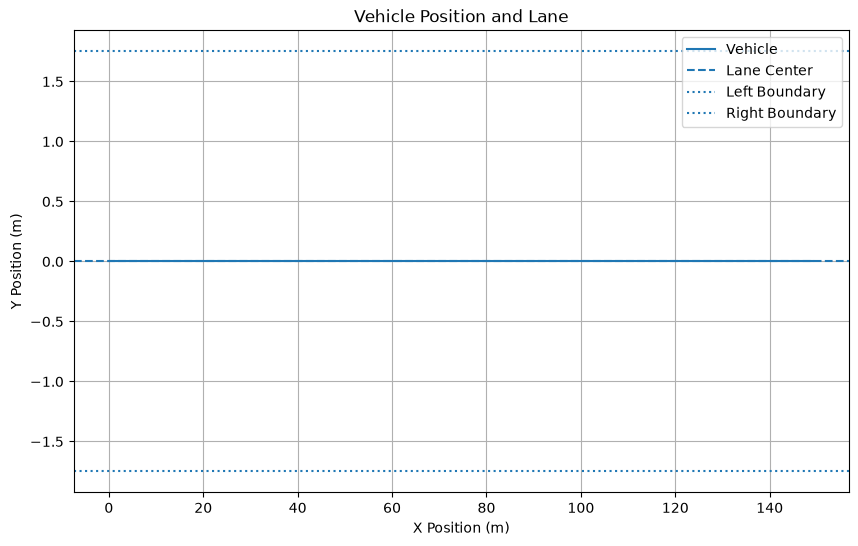

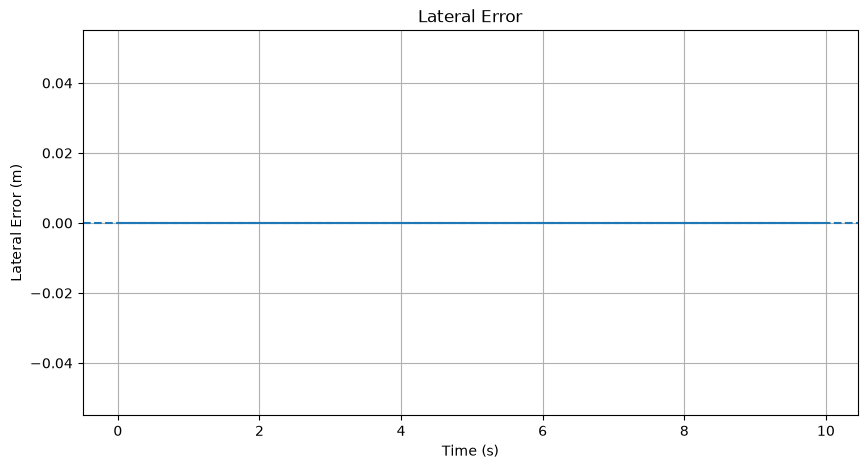

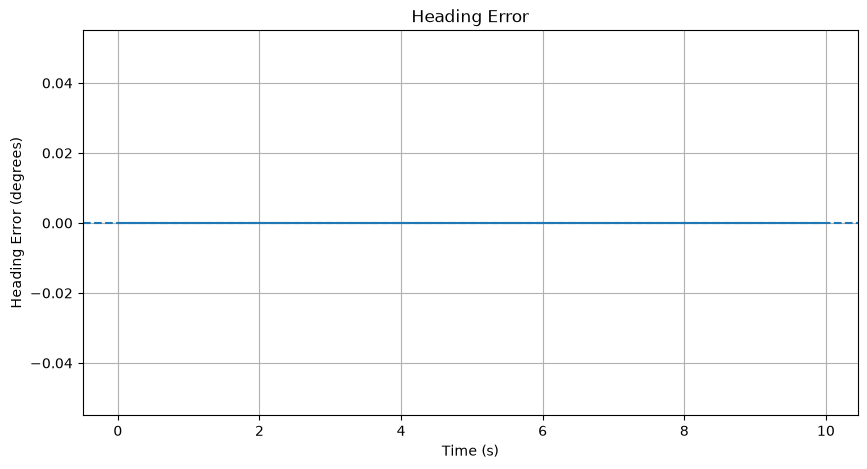

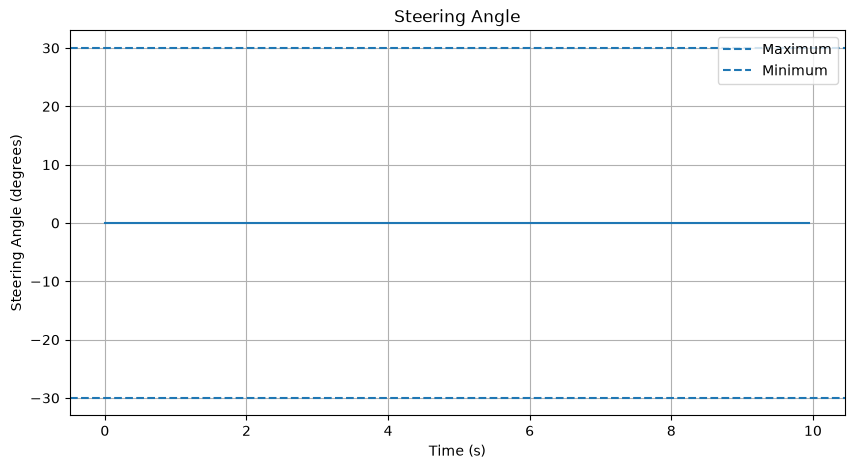

In [23]:
h = simulator.history

plt.figure(figsize=(10, 6))
plt.plot(h["x"], h["y"], label="Vehicle")
plt.axhline(lane_state.center, linestyle="--", label="Lane Center")
plt.axhline(lane_state.center + lane_state.width / 2, linestyle=":", label="Left Boundary")
plt.axhline(lane_state.center - lane_state.width / 2, linestyle=":", label="Right Boundary")
plt.xlabel("X Position (m)"); plt.ylabel("Y Position (m)"); plt.title("Vehicle Position and Lane")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(10, 5))
plt.plot(h["time"], h["lateral_error"])
plt.axhline(0, linestyle="--")
plt.xlabel("Time (s)"); plt.ylabel("Lateral Error (m)"); plt.title("Lateral Error")
plt.grid(True); plt.show()

plt.figure(figsize=(10, 5))
plt.plot(h["time"], np.rad2deg(h["heading_error"]))
plt.axhline(0, linestyle="--")
plt.xlabel("Time (s)"); plt.ylabel("Heading Error (degrees)"); plt.title("Heading Error")
plt.grid(True); plt.show()

plt.figure(figsize=(10, 5))
plt.plot(h["time"], np.rad2deg(h["steering"]))
plt.axhline(np.rad2deg(control_params.max_steering_angle), linestyle="--", label="Maximum")
plt.axhline(-np.rad2deg(control_params.max_steering_angle), linestyle="--", label="Minimum")
plt.xlabel("Time (s)"); plt.ylabel("Steering Angle (degrees)"); plt.title("Steering Angle")
plt.legend(); plt.grid(True); plt.show()


## 14. Pruebas unitarias (casos de prueba, sección 26 del documento)

Estas pruebas **no dependen de ninguna imagen ni video**: son casos inventados a mano
para verificar que la lógica de decisión (matemática pura) se comporta como se espera.
Sirve para demostrar el requisito RNF-09 ("capacidad de probar cada módulo
independientemente") sin necesitar cámara, YOLOPv2 ni GPU.


In [24]:
def run_case(name, condition, detail=""):
    status = "PASS" if condition else "FAIL"
    print(f"[{status}] {name} {detail}")

print("=== CASOS DE LANE KEEPING ===\n")

lane = LaneState(center=0.0, heading=0.0, width=3.5)
control = LaneKeepingController(ControlParams())

e_y = LaneGeometry.lateral_error(vehicle_y=0.0, lane=lane)
e_psi = LaneGeometry.heading_error(vehicle_yaw=0.0, lane=lane)
steering = control.compute_steering(e_y, e_psi)
run_case("Vehiculo centrado en carril", e_y == 0.0 and e_psi == 0.0 and steering == 0.0)

e_y = LaneGeometry.lateral_error(vehicle_y=1.5, lane=lane)
steering = control.compute_steering(e_y, heading_error=0.0)
run_case("Acercandose al limite izquierdo -> corrige a la derecha", steering < 0, f"(steering={steering:.3f})")

e_y = LaneGeometry.lateral_error(vehicle_y=-1.5, lane=lane)
steering = control.compute_steering(e_y, heading_error=0.0)
run_case("Acercandose al limite derecho -> corrige a la izquierda", steering > 0, f"(steering={steering:.3f})")

vehicle = VehicleParams()
safety = SafetyParams()
run_case("Vehiculo muy desviado -> detecta riesgo de salida",
         LaneGeometry.is_departing(2.0, lane, vehicle, safety) == True)
run_case("Vehiculo centrado -> NO detecta riesgo de salida",
         LaneGeometry.is_departing(0.0, lane, vehicle, safety) == False)

print("\n=== CASOS DE LANE-CHANGE VALIDATION ===\n")

validator = LaneChangeValidator(SafetyParams())
ego = VehicleState(x=0.0, y=0.0, yaw=0.0, speed=15.0)

run_case("Carril objetivo vacio -> permite cambio",
         validator.can_change_lane("LEFT", ego, 0, []) == True)

far_ahead = [TrackedObject(1, x=60.0, y=0.0, speed=14.0, lane=1)]
run_case("Vehiculo lejano delante -> permite cambio",
         validator.can_change_lane("LEFT", ego, 0, far_ahead) == True)

near_ahead = [TrackedObject(1, x=5.0, y=0.0, speed=14.0, lane=1)]
run_case("Vehiculo cercano delante -> rechaza cambio",
         validator.can_change_lane("LEFT", ego, 0, near_ahead) == False)

two_objects = [
    TrackedObject(1, x=60.0, y=0.0, speed=14.0, lane=1),
    TrackedObject(2, x=5.0, y=0.0, speed=14.0, lane=1),
]
run_case("Dos vehiculos, uno inseguro -> rechaza cambio",
         validator.can_change_lane("LEFT", ego, 0, two_objects) == False)

invalid_data = [TrackedObject(1, x=60.0, y=0.0, speed=14.0, lane=1, data_is_valid=False)]
run_case("Dato invalido en carril objetivo -> rechaza (conservador)",
         validator.can_change_lane("LEFT", ego, 0, invalid_data) == False)

print("\nSi todos salen [PASS], la logica de decision funciona como describe la seccion 26 del documento.")


=== CASOS DE LANE KEEPING ===

[PASS] Vehiculo centrado en carril 
[PASS] Acercandose al limite izquierdo -> corrige a la derecha (steering=-0.524)
[PASS] Acercandose al limite derecho -> corrige a la izquierda (steering=0.524)
[PASS] Vehiculo muy desviado -> detecta riesgo de salida 
[PASS] Vehiculo centrado -> NO detecta riesgo de salida 

=== CASOS DE LANE-CHANGE VALIDATION ===

[PASS] Carril objetivo vacio -> permite cambio 
[PASS] Vehiculo lejano delante -> permite cambio 
[PASS] Vehiculo cercano delante -> rechaza cambio 
[PASS] Dos vehiculos, uno inseguro -> rechaza cambio 
[PASS] Dato invalido en carril objetivo -> rechaza (conservador) 

Si todos salen [PASS], la logica de decision funciona como describe la seccion 26 del documento.
